In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

In [3]:
df = pd.read_csv(r"D:\Semester 5\NLP\modul-1\dataset_preprocessed.csv")
text_column = "text_original"  # gunakan teks asli (sebelum preprocessing)
df = df.dropna(subset=[text_column])
sample_texts = df[text_column].head(100).astype(str).tolist()
print(f"Jumlah sample: {len(sample_texts)}")

Jumlah sample: 100


In [5]:
from gensim.models import Word2Vec

# Load model Word2Vec yang sudah dilatih sebelumnya
# (atau latih ulang jika diperlukan)
model_w2v = Word2Vec.load(
    r"D:\Semester 5\NLP\Modul - 2\word2vec_model.bin"
)

# Kata yang sama dalam konteks berbeda
ambiguous_sentences = [
    "ular itu berbisa mematikan",
    "saya bisa berenang jauh",
    "obat itu manjur bisa menyembuhkan"
]

print("Demonstrasi Keterbatasan Static Embedding:")
print("=" * 60)
print("Kata 'bisa' selalu memiliki vektor yang SAMA:")

if "bisa" in model_w2v.wv:
    vec = model_w2v.wv["bisa"]
    print(f"  Vektor 'bisa' (10 dim pertama): {vec[:10].round(3)}")
else:
    print("  Kata 'bisa' tidak ada dalam vocabulary model ini.")
    print("  Gunakan kata lain yang tersedia sebagai contoh.")

Demonstrasi Keterbatasan Static Embedding:
Kata 'bisa' selalu memiliki vektor yang SAMA:
  Vektor 'bisa' (10 dim pertama): [-0.1    0.223 -0.05   0.049  0.197 -0.212  0.089  0.18  -0.129 -0.015]


In [2]:
# Model multilingual yang mendukung Bahasa Indonesia
model_st = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
print("Model Sentence Transformer berhasil dimuat.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model Sentence Transformer berhasil dimuat.


In [ ]:
if "sample_texts" not in globals():
    df = pd.read_csv(r"D:\Semester 5\NLP\modul-1\dataset_preprocessed.csv")
    text_column = "text_original"
    df = df.dropna(subset=[text_column])
    sample_texts = df[text_column].head(100).astype(str).tolist()

# Encode kalimat menjadi vektor
embeddings = model_st.encode(sample_texts, show_progress_bar=True)

print(f"Shape embeddings: {embeddings.shape}")
print(f"Dimensi per kalimat: {embeddings.shape[1]}")

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Shape embeddings: (100, 384)
Dimensi per kalimat: 384


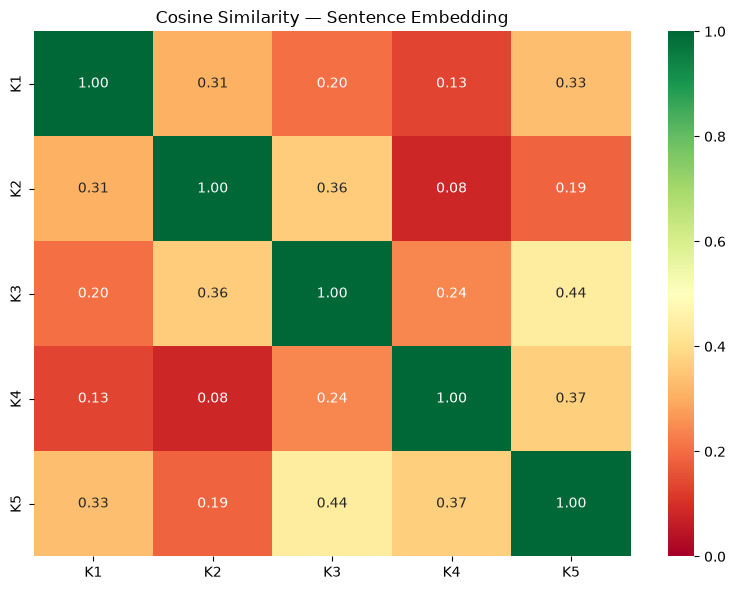

K1: Bang  kumis memiliki karakter salesman yg kuat. Ciri khasnya selalu mengulang2  ...
K2: Saya nonton krn ada Bang Hensa,dgn Fery Amsari......
K3: dr awal MBG di kritik rakyat,tp yg kritik di blng antek asing!rakyat lbh th dr p...
K4: Kalau maling uang rakyat tidak di hukum mati,, jangan harap negara ini maju...
K5: Jubirnya kata2nya manis pdhl omdo, dilapangan rakyat tdk di lubatkan dlm MBG, ju...


In [5]:
# Ambil 5 kalimat pertama
test_sentences = sample_texts[:5]
test_embeddings = model_st.encode(test_sentences)

# Hitung cosine similarity
sim_matrix = cosine_similarity(test_embeddings)

# Visualisasi
plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0, vmax=1,
    xticklabels=[f"K{i+1}" for i in range(5)],
    yticklabels=[f"K{i+1}" for i in range(5)]
)
plt.title("Cosine Similarity — Sentence Embedding")
plt.tight_layout()
plt.show()

# Tampilkan kalimat
for i, text in enumerate(test_sentences):
    print(f"K{i+1}: {text[:80]}...")

In [6]:
# Kata ambigu dalam konteks berbeda
context_pairs = [
    ("Bunga mawar merah itu sangat indah.", "Bunga tabungan bank naik bulan ini."),
    ("Kita harus bisa menyelesaikan masalah ini.", "Ular kobra itu sangat berbisa."),
    ("Dia pergi ke bank untuk menabung.", "Mereka duduk di tepi kali yang jernih."),
]

print("Perbandingan Semantic Similarity Konteks Berbeda:")
print("=" * 60)
for s1, s2 in context_pairs:
    e1 = model_st.encode([s1])
    e2 = model_st.encode([s2])
    sim = cosine_similarity(e1, e2)[0][0]
    print(f"\nK1: {s1}")
    print(f"K2: {s2}")
    print(f"Similarity: {sim:.4f} ({'mirip' if sim > 0.7 else 'berbeda'})")

Perbandingan Semantic Similarity Konteks Berbeda:

K1: Bunga mawar merah itu sangat indah.
K2: Bunga tabungan bank naik bulan ini.
Similarity: 0.0560 (berbeda)

K1: Kita harus bisa menyelesaikan masalah ini.
K2: Ular kobra itu sangat berbisa.
Similarity: -0.0270 (berbeda)

K1: Dia pergi ke bank untuk menabung.
K2: Mereka duduk di tepi kali yang jernih.
Similarity: 0.0549 (berbeda)


In [7]:
def semantic_search(query, corpus_embeddings, corpus_texts, top_n=5):
    query_embedding = model_st.encode([query])
    similarities = cosine_similarity(query_embedding, corpus_embeddings)[0]
    top_indices = similarities.argsort()[::-1][:top_n]
    results = []
    for idx in top_indices:
        results.append({
            "score": similarities[idx],
            "text": corpus_texts[idx]
        })
    return results

# Contoh pencarian semantik
query = "pelayanan hotel yang memuaskan"
results = semantic_search(query, embeddings, sample_texts)

print(f"Query: '{query}'")
print("=" * 60)
for i, res in enumerate(results, 1):
    print(f"\n{i}. [Score: {res['score']:.4f}]")
    print(f"   {res['text'][:120]}...")

Query: 'pelayanan hotel yang memuaskan'

1. [Score: 0.2399]
   Hensat top markotop 👍...

2. [Score: 0.2355]
   Dikasi bintang jasa pula ni si Dadan,luar biase...

3. [Score: 0.2306]
   Terima kasih bang Ferry,bang Heksa dan bang Media...sdh menyuarakan yg terbaik demi kelangsungan bangsa dan negara ini.....

4. [Score: 0.2039]
   Bang Ferry is the best ,lanjutkan anda mewakili suara rakyat yg mempunyai paradigma dan mind set yg sama demi indonesia ...

5. [Score: 0.1863]
   Saya apresiasi publik speaking juru bicara partai Gerinda ini sangat pelan² dan tidak terbawa suasana 😁...


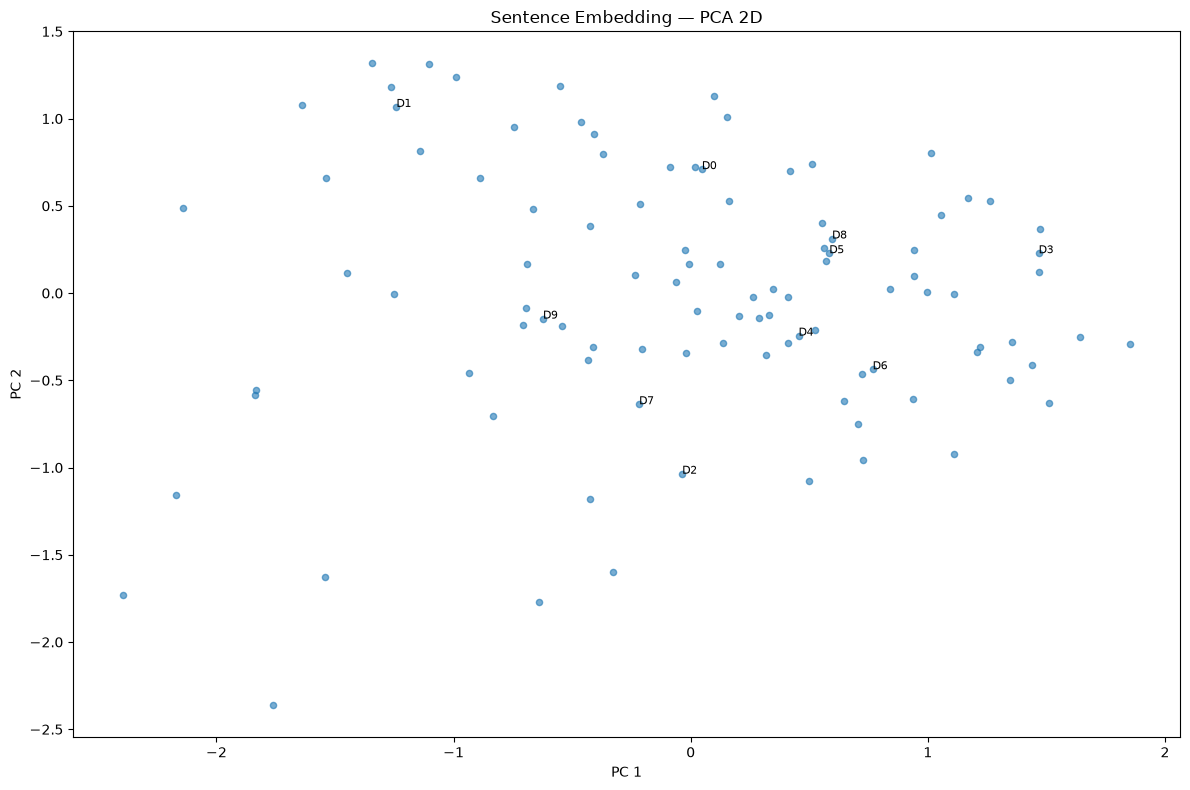

Variansi yang dijelaskan: 20.62%


In [8]:
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)

plt.figure(figsize=(12, 8))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], alpha=0.6, s=20)

# Highlight beberapa dokumen
for i in range(min(10, len(sample_texts))):
    plt.annotate(
        f"D{i}",
        xy=(embeddings_2d[i, 0], embeddings_2d[i, 1]),
        fontsize=8
    )

plt.title("Sentence Embedding — PCA 2D")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.tight_layout()
plt.show()

print(f"Variansi yang dijelaskan: {pca.explained_variance_ratio_.sum():.2%}")

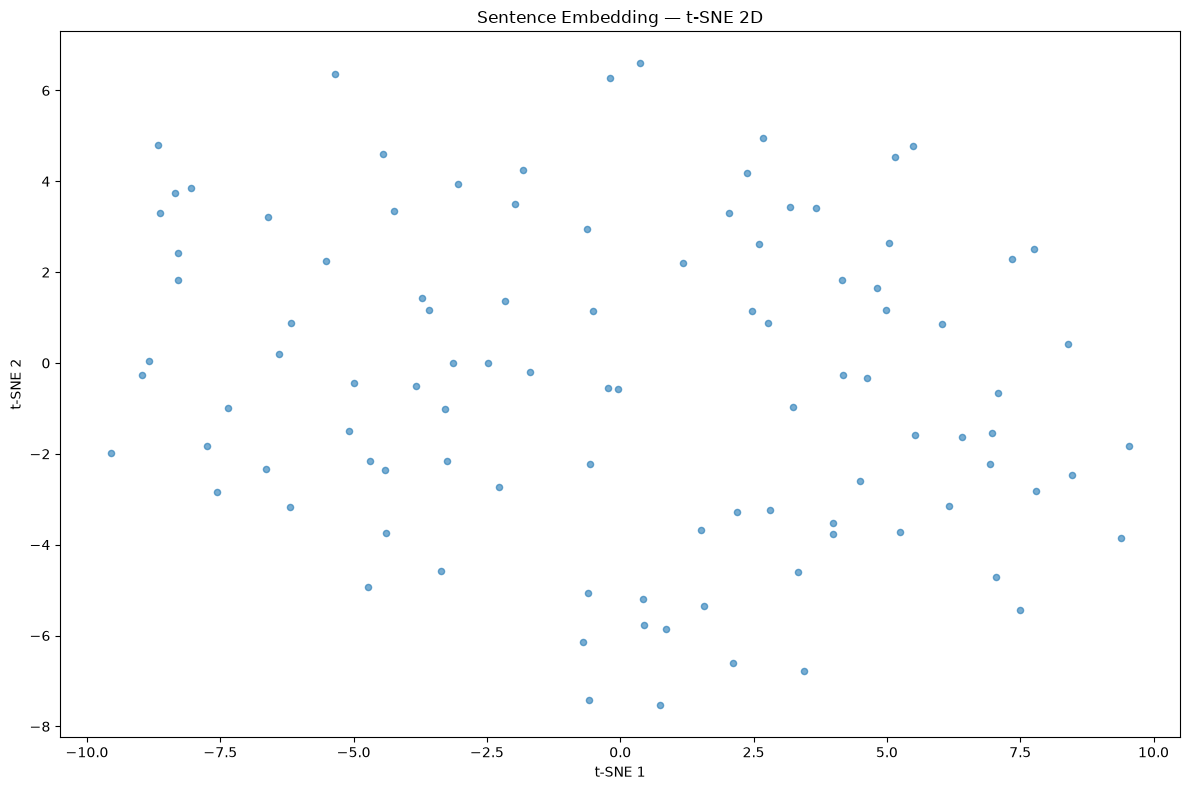

In [13]:
tsne = TSNE(n_components=2, perplexity=20, random_state=42, max_iter=1000)
embeddings_tsne = tsne.fit_transform(embeddings)

plt.figure(figsize=(12, 8))
plt.scatter(embeddings_tsne[:, 0], embeddings_tsne[:, 1], alpha=0.6, s=20)
plt.title("Sentence Embedding — t-SNE 2D")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

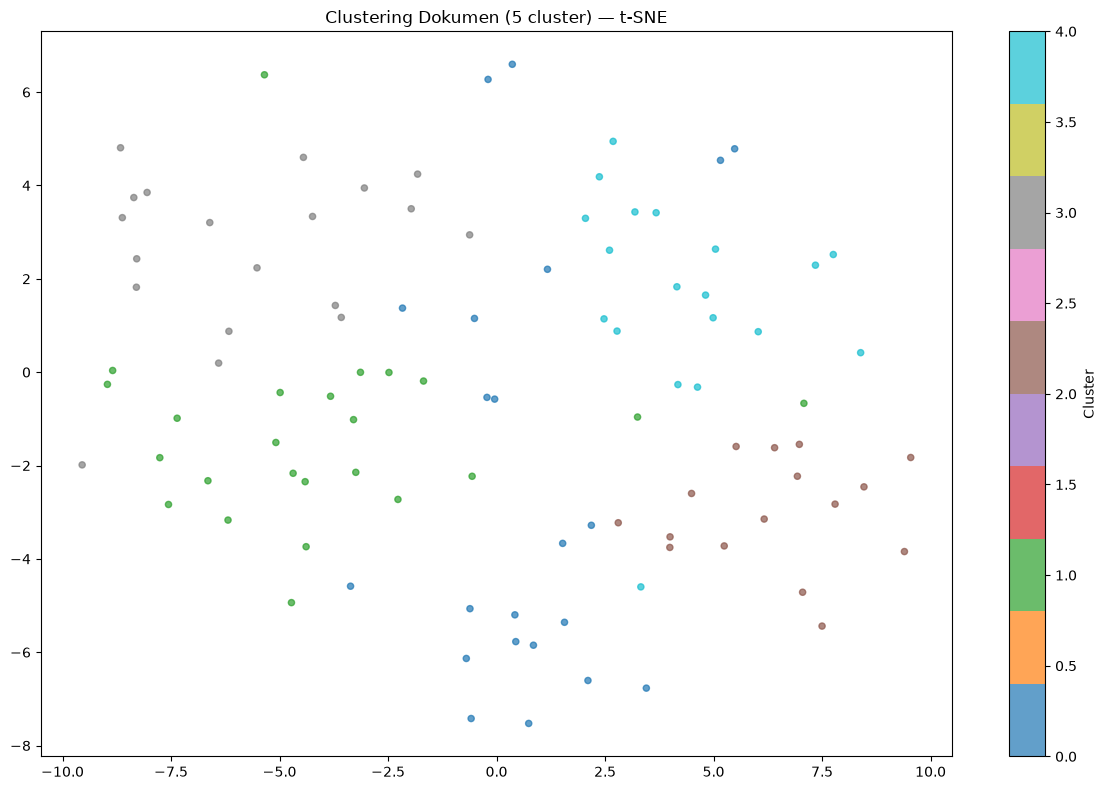


Cluster 0 (contoh dokumen):
  - Kalau maling uang rakyat tidak di hukum mati,, jangan harap negara ini maju...
  - KopDes mohon disegerakan diaudit dan segera ditangkap petinggi2 dan kroni2nya,ti...
  - Saran saya kepada saluran tv. Undang saja perwakilan dari masyarakat yg menengah...

Cluster 1 (contoh dokumen):
  - Bang  kumis memiliki karakter salesman yg kuat. Ciri khasnya selalu mengulang2  ...
  - Saya nonton krn ada Bang Hensa,dgn Fery Amsari......
  - Kenapa tidak orang seperti bang Ferry yang masuk pemerintahan ..... biar kapok t...

Cluster 2 (contoh dokumen):
  - anak bangsa itu tdk butuh makan gratis , tpi anak bangsa butuh orang tua nya bis...
  - COBA DISURVE.
PASTI LEBIH BANYAK YG SETUJU MBG DIBUBARKAN. Yg rugi yg punya dapu...
  - Tutup mbg,anak orang kaya.ikut makan,tutup mbg dan uangnya kasihkan rakyat yang ...

Cluster 3 (contoh dokumen):
  - dr awal MBG di kritik rakyat,tp yg kritik di blng antek asing!rakyat lbh th dr p...
  - Bang Ferry is the best ,lanjutkan an

In [14]:
from sklearn.cluster import KMeans

# Cluster dokumen menjadi 5 kelompok
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(embeddings)

# Visualisasi cluster
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    embeddings_tsne[:, 0],
    embeddings_tsne[:, 1],
    c=cluster_labels,
    cmap="tab10",
    alpha=0.7,
    s=20
)
plt.colorbar(scatter, label="Cluster")
plt.title(f"Clustering Dokumen ({n_clusters} cluster) — t-SNE")
plt.tight_layout()
plt.show()

# Contoh dokumen per cluster
for cluster_id in range(n_clusters):
    indices = np.where(cluster_labels == cluster_id)[0][:3]
    print(f"\nCluster {cluster_id} (contoh dokumen):")
    for idx in indices:
        print(f"  - {sample_texts[idx][:80]}...")